In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import AgglomerativeClustering

In [3]:
df =pd.read_csv("Country-data.csv")

In [4]:
df.head

<bound method NDFrame.head of                  Country  Child_Mort  Exports  Health  Imports  Income  \
0            Afghanistan        90.2     10.0    7.58     44.9    1610   
1                Albania        16.6     28.0    6.55     48.6    9930   
2                Algeria        27.3     38.4    4.17     31.4   12900   
3                 Angola       119.0     62.3    2.85     42.9    5900   
4    Antigua and Barbuda        10.3     45.5    6.03     58.9   19100   
..                   ...         ...      ...     ...      ...     ...   
162              Vanuatu        29.2     46.6    5.25     52.7    2950   
163            Venezuela        17.1     28.5    4.91     17.6   16500   
164              Vietnam        23.3     72.0    6.84     80.2    4490   
165                Yemen        56.3     30.0    5.18     34.4    4480   
166               Zambia        83.1     37.0    5.89     30.9    3280   

     Inflation  Life_Expec  Total_Fer   GDPP  
0         9.44        56.2       5

In [5]:
X = df.drop("Country", axis=1)


In [6]:
X

,Child_Mort,Exports,Health,Imports,Income,Inflation,Life_Expec,Total_Fer,GDPP
0,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553
1,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090
2,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460
3,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530
4,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200
...,...,...,...,...,...,...,...,...,...
162,29.2,46.6,5.25,52.7,2950,2.62,63.0,3.50,2970
163,17.1,28.5,4.91,17.6,16500,45.90,75.4,2.47,13500
164,23.3,72.0,6.84,80.2,4490,12.10,73.1,1.95,1310
165,56.3,30.0,5.18,34.4,4480,23.60,67.5,4.67,1310


In [16]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

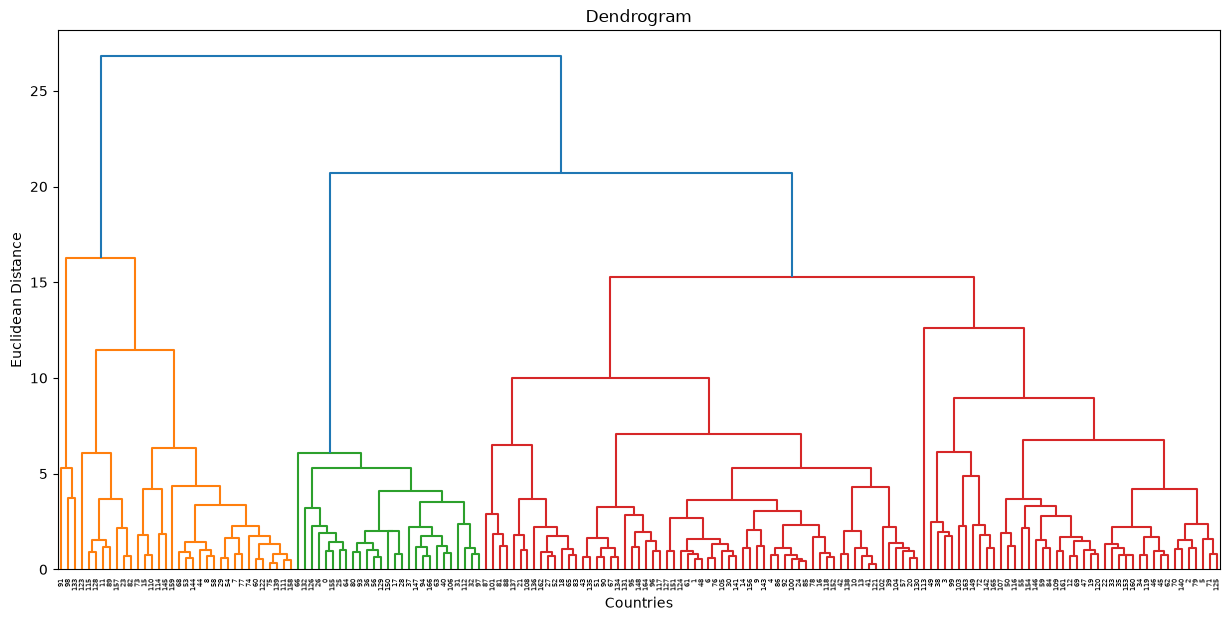

In [15]:
plt.figure(figsize=(15, 7))

dendrogram = sch.dendrogram(
    sch.linkage(X_scaled, method='ward')
)

plt.title("Dendrogram")
plt.xlabel("Countries")
plt.ylabel("Euclidean Distance")
plt.show()

In [8]:
model = AgglomerativeClustering(n_clusters=3)

clusters = model.fit_predict(X)

In [10]:
df["Cluster"] = clusters

print(df.head())

               Country  Child_Mort  Exports  Health  Imports  Income  \
0          Afghanistan        90.2     10.0    7.58     44.9    1610   
1              Albania        16.6     28.0    6.55     48.6    9930   
2              Algeria        27.3     38.4    4.17     31.4   12900   
3               Angola       119.0     62.3    2.85     42.9    5900   
4  Antigua and Barbuda        10.3     45.5    6.03     58.9   19100   

   Inflation  Life_Expec  Total_Fer   GDPP  Cluster  
0       9.44        56.2       5.82    553        2  
1       4.49        76.3       1.65   4090        2  
2      16.10        76.5       2.89   4460        2  
3      22.40        60.1       6.16   3530        2  
4       1.44        76.8       2.13  12200        1  


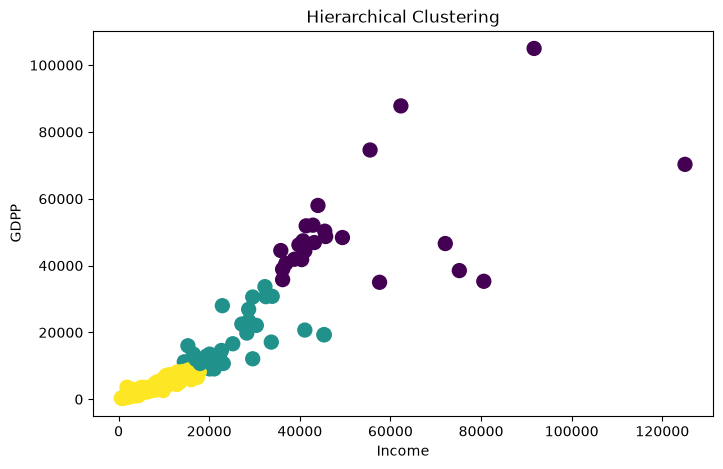

In [23]:
plt.figure(figsize=(8,5))

plt.scatter(
    X["Income"],
    X["GDPP"],
    c=clusters,
    s=100
)

plt.title("Hierarchical Clustering")
plt.xlabel("Income")
plt.ylabel("GDPP")

plt.show()